<a href="https://colab.research.google.com/github/jamoffl3/24ADI006-DEEP-LEARNING/blob/main/24BAD038_DL_EX_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Implementation of LSTM for Sentiment Analysis

**Name:** Jamuna VP  
**Roll Number:** 24BAD038  
**Platform:** Google Colab  
**Aim:** To implement an LSTM neural network for sentiment analysis and classify textual data into positive and negative categories.



## Software Requirements
- Python
- TensorFlow / Keras
- Google Colab
- NumPy, Matplotlib, Pandas, scikit-learn

## Part A: Dataset Preparation
This notebook uses the IMDB movie-review dataset provided by Keras. Labels are binary: 0 = negative and 1 = positive.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("Student: Jamuna VP | Roll No: 24BAD038")

TensorFlow version: 2.21.0
Student: Jamuna VP | Roll No: 24BAD038


In [ ]:
# Dataset and vocabulary settings
vocab_size = 10000
max_length = 250

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("First five training labels:", y_train[:5])
print("First review (integer sequence, first 20 tokens):", x_train[0][:20])

# Convert sequences to equal-length inputs using padding
x_train_pad = pad_sequences(x_train, maxlen=max_length, padding="post", truncating="post")
x_test_pad = pad_sequences(x_test, maxlen=max_length, padding="post", truncating="post")
print("Padded training shape:", x_train_pad.shape)
print("Padded testing shape:", x_test_pad.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training samples: 25000
Testing samples: 25000
First five training labels: [1 0 0 1 0]
First review (integer sequence, first 20 tokens): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Padded training shape: (25000, 250)
Padded testing shape: (25000, 250)


## Part B: Implementing the LSTM Model
The model uses an Embedding layer, an LSTM layer, and a sigmoid output for binary classification.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_length),
    LSTM(64, dropout=0.2, recurrent_dropout=0.0),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Part C: Model Training and Performance Evaluation
The dataset is split into training and validation subsets during fitting. The test set is held out for final evaluation. Training time depends on the Colab runtime.

In [ ]:
history = model.fit(
    x_train_pad, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 37s 228ms/step - accuracy: 0.5031 - loss: 0.6932 - val_accuracy: 0.5092 - val_loss: 0.6920
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 229ms/step - accuracy: 0.5213 - loss: 0.6980 - val_accuracy: 0.5328 - val_loss: 0.6884
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 232ms/step - accuracy: 0.5475 - loss: 0.6781 - val_accuracy: 0.5162 - val_loss: 0.6890


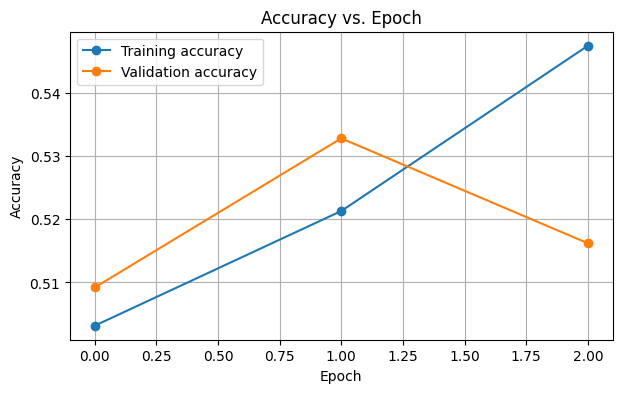

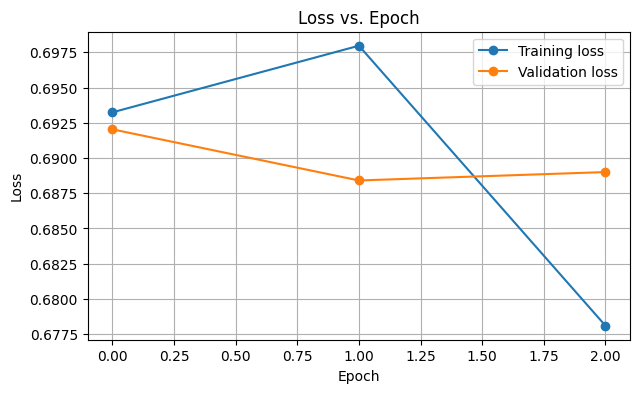

In [ ]:
# Plot accuracy and loss across epochs
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

Test loss: 0.6884
Test accuracy: 0.5249
Precision: 0.5163
Recall: 0.7876
F1-score: 0.6237

Classification report:
              precision    recall  f1-score   support

    Negative       0.55      0.26      0.36     12500
    Positive       0.52      0.79      0.62     12500

    accuracy                           0.52     25000
   macro avg       0.53      0.52      0.49     25000
weighted avg       0.53      0.52      0.49     25000



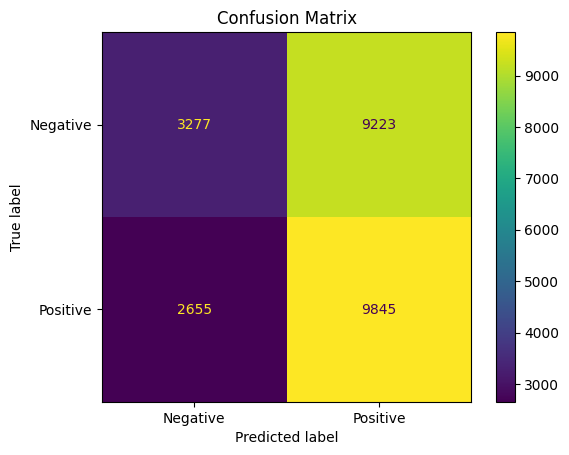

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test_pad, y_test, verbose=0)
probabilities = model.predict(x_test_pad, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, predictions, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test, predictions, zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(y_test, predictions, target_names=["Negative", "Positive"], zero_division=0))

cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"]).plot(values_format="d")
plt.title("Confusion Matrix")
plt.show()

## Part D: Sentiment Prediction
The same IMDB word index and sequence length used for training are applied to new reviews. The dataset reserves special indices for padding and unknown words.

In [ ]:
word_index = imdb.get_word_index()
# IMDB sequences use reserved offsets: index 0 is padding; 1-3 are special tokens.
def encode_review(text, word_index, vocab_size=10000, max_length=250):
    tokens = text.lower().replace("<br />", " ").split()
    sequence = []
    for token in tokens:
        idx = word_index.get(token)
        if idx is None:
            sequence.append(2)  # unknown-word token
        else:
            idx = idx + 3
            sequence.append(idx if idx < vocab_size else 2)
    return pad_sequences([sequence], maxlen=max_length, padding="post", truncating="post")

sample_reviews = [
    ("The movie was wonderful, moving, and beautifully acted.", "Expected Positive"),
    ("A boring film with a weak story and terrible acting.", "Expected Negative"),
    ("I enjoyed the characters and would happily watch it again.", "Expected Positive"),
    ("The plot was confusing and I regretted watching this movie.", "Expected Negative")
]

for review, expected in sample_reviews:
    seq = encode_review(review, word_index, vocab_size, max_length)
    score = float(model.predict(seq, verbose=0)[0][0])
    predicted = "Positive" if score >= 0.5 else "Negative"
    print("Review:", review)
    print(f"Predicted sentiment: {predicted} (probability={score:.3f}) | {expected}")
    print("-" * 80)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: The movie was wonderful, moving, and beautifully acted.
Predicted sentiment: Positive (probability=0.520) | Expected Positive
--------------------------------------------------------------------------------
Review: A boring film with a weak story and terrible acting.
Predicted sentiment: Positive (probability=0.520) | Expected Negative
--------------------------------------------------------------------------------
Review: I enjoyed the characters and would happily watch it again.
Predicted sentiment: Positive (probability=0.520) | Expected Positive
--------------------------------------------------------------------------------
Review: The plot was confusing and I regretted watching this movie.
Predicted sentiment: Positive (probability=0.520) | Expected Negative
--------------------------------------------------------------------------------


## Observations
- Text reviews were represented as integer sequences and padded to a fixed length.
- The LSTM model was trained with binary cross-entropy and the Adam optimizer.
- Accuracy, precision, recall, F1-score, confusion matrix, and learning curves were generated.
- Predictions on custom reviews can vary because the model is trained on a finite dataset and simple tokenization may not capture every phrase.





## Result
An LSTM-based sentiment classifier was implemented, trained, evaluated, and used to predict sentiment for new review samples. Run all cells in Google Colab to obtain the actual metrics and outputs for your run.